# Zimbabwe extra inputs: coverage and model-fit audit

This notebook audits the completed Zimbabwe extraction for the missing Presto channels and the proposed field-level extensions. It reports actual coverage, spatial usefulness, quality checks, and remaining modelling limitations.

In [1]:
from pathlib import Path
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().resolve()
if REPO.name == 'notebooks': REPO = REPO.parent
ROOT = Path(os.environ.get(
    'CROPYIELD_EXTRA_INPUTS_ROOT',
    REPO.parent / 'presto_extra_inputs_2026-11-09',
)).expanduser().resolve()
DERIVED, REPORTS = ROOT / 'derived', ROOT / 'reports'
fields = pd.read_csv(DERIVED / 'zimbabwe_fields_2022_2023.csv')
monthly = pd.read_csv(DERIVED / 'model_ready_monthly_extra_inputs.csv')
static = pd.read_csv(DERIVED / 'model_ready_static_extra_inputs.csv')
summary = json.loads((REPORTS / 'combined_inputs_summary.json').read_text(encoding='utf-8'))
print(f"{len(fields):,} observations; {len(monthly):,} observation-month rows")
print(f"Seasons: {fields.groupby('season_year').size().to_dict()}")
print(f"Geometry: {fields['geometry_type'].value_counts().to_dict()}")

2,266 observations; 20,394 observation-month rows
Seasons: {2022: 169, 2023: 2097}
Geometry: {'Point': 2266}


## 1. Final source completeness

All six Earth Engine batches have been integrated. The chart uses observations as the denominator for static data and observation-months for monthly data. Sentinel-1 is shown separately because its sparse acquisition coverage is the main limitation.

,source,complete,expected,percent
0,SRTM,2266,2266,100.000000
1,SoilGrids,2265,2266,99.955869
2,CHIRPS,20394,20394,100.000000
3,ERA5-Land,20394,20394,100.000000
4,AlphaEarth,2266,2266,100.000000
5,Sentinel-1,704,20394,3.451996


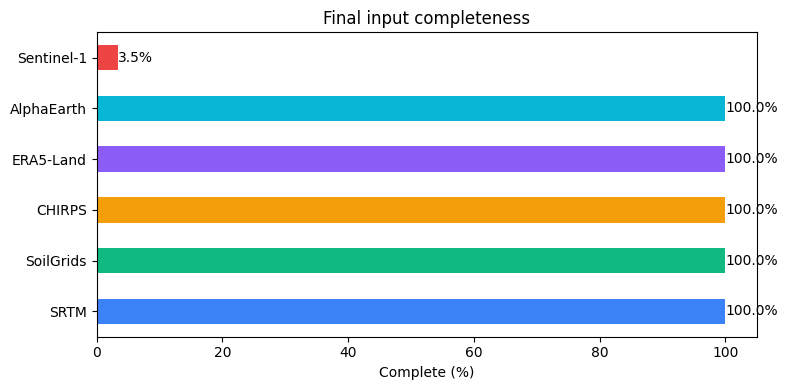

In [2]:
coverage = pd.DataFrame({
    'source': ['SRTM', 'SoilGrids', 'CHIRPS', 'ERA5-Land', 'AlphaEarth', 'Sentinel-1'],
    'complete': [summary['srtm_local_complete_observations'], summary['soilgrids_complete_observations'], summary['chirps_complete_rows'], summary['gee_audit']['era5_complete_rows'], summary['gee_audit']['alphaearth_complete_observations'], summary['gee_audit']['s1_complete_rows']],
    'expected': [len(fields), len(fields), len(monthly), len(monthly), len(fields), len(monthly)]
})
coverage['percent'] = 100 * coverage['complete'] / coverage['expected']
display(coverage)
ax = coverage.plot.barh(x='source', y='percent', legend=False, color=['#3b82f6','#10b981','#f59e0b','#8b5cf6','#06b6d4','#ef4444'], figsize=(8,4))
ax.set(xlabel='Complete (%)', ylabel='', xlim=(0,105), title='Final input completeness')
for container in ax.containers: ax.bar_label(container, fmt='%.1f%%')
plt.tight_layout(); plt.show()

## 2. Can a source vary inside a 2 km village?

Resolution alone does not guarantee useful within-village variation. We join the repository's 2 km clusters and count how often a multi-observation cluster contains more than one source value or grid cell. CHIRPS is expected to vary rarely; SRTM and 250 m soils can vary more often.

In [3]:
labels = pd.read_parquet(REPO / 'data' / 'processed' / 'labels_v1.parquet', columns=['obs_id','cluster_2km'])
audit = static.merge(labels, on='obs_id', how='left', validate='one_to_one')
multi = audit.groupby('cluster_2km').filter(lambda g: len(g) > 1)
variables = {
    'SRTM elevation (30 m)': 'srtm_elevation_m_point',
    'Soil pH cell (250 m)': 'soilgrids_phh2o_0_5cm_mean_cell',
    'Soil SOC cell (250 m)': 'soilgrids_soc_0_5cm_mean_cell',
}
rows=[]
for label, col in variables.items():
    per_cluster = multi.groupby('cluster_2km')[col].nunique(dropna=True)
    rows.append({'source': label, 'multi-field clusters': len(per_cluster), 'clusters with >1 value': int((per_cluster>1).sum()), 'share varying': float((per_cluster>1).mean())})
variation = pd.DataFrame(rows)
display(variation.style.format({'share varying':'{:.1%}'}))

,source,multi-field clusters,clusters with >1 value,share varying
0,SRTM elevation (30 m),198,198,100.0%
1,Soil pH cell (250 m),198,194,98.0%
2,Soil SOC cell (250 m),198,194,98.0%


## 3. Monthly coverage and weather consistency

Every observation has the same nine-month October–June window. CHIRPS and ERA5-Land are complete and strongly correlated, but both are too coarse to represent field-scale differences. Sentinel-1 coverage drops sharply after December 2021, consistent with the loss of Sentinel-1B and the revised one-satellite acquisition plan.

,month,expected_rows,s1_complete_rows,era5_complete_rows,srtm_complete_rows,s1_complete_pct,era5_complete_pct,srtm_complete_pct
0,2021-10,169,169,169,169,100.000000,100.0,100.0
1,2021-11,169,169,169,169,100.000000,100.0,100.0
2,2021-12,169,169,169,169,100.000000,100.0,100.0
3,2022-01,169,31,169,169,18.343195,100.0,100.0
4,2022-02,169,31,169,169,18.343195,100.0,100.0
5,2022-03,169,31,169,169,18.343195,100.0,100.0
6,2022-04,169,31,169,169,18.343195,100.0,100.0
7,2022-05,169,31,169,169,18.343195,100.0,100.0
8,2022-06,169,31,169,169,18.343195,100.0,100.0
9,2022-10,2097,0,2097,2097,0.000000,100.0,100.0


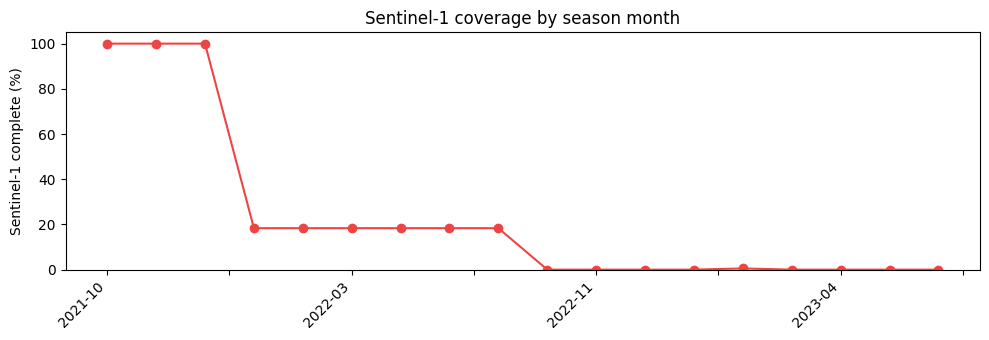

CHIRPS–ERA5 precipitation correlation: 0.851
Unique CHIRPS cells: 416
Sentinel-1 observations with all 9 months: 31


In [4]:
month_counts = pd.read_csv(REPORTS / 'monthly_source_coverage.csv')
display(month_counts)
ax = month_counts.plot(x='month', y='s1_complete_pct', marker='o', color='#ef4444', figsize=(10,3.5), legend=False)
ax.set(ylabel='Sentinel-1 complete (%)', xlabel='', ylim=(0,105), title='Sentinel-1 coverage by season month')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()
quality = json.loads((REPORTS / 'feature_quality_summary.json').read_text(encoding='utf-8'))
print('CHIRPS–ERA5 precipitation correlation:', round(quality['chirps_era5_precipitation_correlation'], 3))
print('Unique CHIRPS cells:', pd.read_csv(DERIVED / 'chirps_monthly.csv')[['chirps_lat','chirps_lon']].drop_duplicates().shape[0])
print('Sentinel-1 observations with all 9 months:', quality['sentinel1_observations_with_all_9_months'])

## 4. Final interpretation and modelling decision

The core extraction is complete: 20,394 unique observation-month keys, nine months per observation, complete ERA5/SRTM, and complete 64-dimensional AlphaEarth embeddings. Sentinel-1 must remain masked where unavailable: only 704 monthly rows and 31 observations with all nine months are complete. The strongest full-sample experiment is therefore Sentinel-2 + ERA5 + SRTM, with SoilGrids and AlphaEarth as separate model arms. Partial Sentinel-1 can be retained with masks, but the 31-point complete subset is too small for the main evaluation. PlanetScope/NICFI remains optional and account-dependent.

In [5]:
status = pd.DataFrame([
    ['SRTM', 'done', '2,266/2,266 observations'],
    ['CHIRPS v2', 'done', '20,394/20,394 rows'],
    ['SoilGrids', 'done with one genuine mask', '2,265/2,266 observations'],
    ['ERA5-Land', 'done', '20,394/20,394 monthly rows'],
    ['AlphaEarth', 'done', '2,266/2,266 observations; 64 dimensions'],
    ['Sentinel-1', 'done but sparse', '704/20,394 monthly rows; 31 complete observations'],
    ['PlanetScope / NICFI', 'optional / account needed', 'coverage check after signup'],
], columns=['source','status','evidence or next action'])
display(status)

,source,status,evidence or next action
0,SRTM,done,"2,266/2,266 observations"
1,CHIRPS v2,done,"20,394/20,394 rows"
2,SoilGrids,done with one genuine mask,"2,265/2,266 observations"
3,ERA5-Land,done,"20,394/20,394 monthly rows"
4,AlphaEarth,done,"2,266/2,266 observations; 64 dimensions"
5,Sentinel-1,done but sparse,"704/20,394 monthly rows; 31 complete observations"
6,PlanetScope / NICFI,optional / account needed,coverage check after signup
